In [126]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

In [ ]:
###load dataset

In [127]:
data = pd.read_csv("sleep_encoded.csv")
data

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Gender_Male,Occupation_Doctor,Occupation_Engineer,...,Blood Pressure_130/86,Blood Pressure_131/86,Blood Pressure_132/87,Blood Pressure_135/88,Blood Pressure_135/90,Blood Pressure_139/91,Blood Pressure_140/90,Blood Pressure_140/95,Blood Pressure_142/92,Sleep Disorder
0,27,6.1,6,42,6,77,4200,True,False,False,...,False,False,False,False,False,False,False,False,False,NaN
1,28,6.2,6,60,8,75,10000,True,True,False,...,False,False,False,False,False,False,False,False,False,NaN
2,28,6.2,6,60,8,75,10000,True,True,False,...,False,False,False,False,False,False,False,False,False,NaN
3,28,5.9,4,30,8,85,3000,True,False,False,...,False,False,False,False,False,False,True,False,False,Sleep Apnea
4,28,5.9,4,30,8,85,3000,True,False,False,...,False,False,False,False,False,False,True,False,False,Sleep Apnea
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,59,8.1,9,75,3,68,7000,False,False,False,...,False,False,False,False,False,False,False,True,False,Sleep Apnea
370,59,8.0,9,75,3,68,7000,False,False,False,...,False,False,False,False,False,False,False,True,False,Sleep Apnea
371,59,8.1,9,75,3,68,7000,False,False,False,...,False,False,False,False,False,False,False,True,False,Sleep Apnea
372,59,8.1,9,75,3,68,7000,False,False,False,...,False,False,False,False,False,False,False,True,False,Sleep Apnea


In [128]:
data.head()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Gender_Male,Occupation_Doctor,Occupation_Engineer,...,Blood Pressure_130/86,Blood Pressure_131/86,Blood Pressure_132/87,Blood Pressure_135/88,Blood Pressure_135/90,Blood Pressure_139/91,Blood Pressure_140/90,Blood Pressure_140/95,Blood Pressure_142/92,Sleep Disorder
0,27,6.1,6,42,6,77,4200,True,False,False,...,False,False,False,False,False,False,False,False,False,NaN
1,28,6.2,6,60,8,75,10000,True,True,False,...,False,False,False,False,False,False,False,False,False,NaN
2,28,6.2,6,60,8,75,10000,True,True,False,...,False,False,False,False,False,False,False,False,False,NaN
3,28,5.9,4,30,8,85,3000,True,False,False,...,False,False,False,False,False,False,True,False,False,Sleep Apnea
4,28,5.9,4,30,8,85,3000,True,False,False,...,False,False,False,False,False,False,True,False,False,Sleep Apnea


In [129]:
data.shape

(374, 46)

In [130]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Age                              374 non-null    int64  
 1   Sleep Duration                   374 non-null    float64
 2   Quality of Sleep                 374 non-null    int64  
 3   Physical Activity Level          374 non-null    int64  
 4   Stress Level                     374 non-null    int64  
 5   Heart Rate                       374 non-null    int64  
 6   Daily Steps                      374 non-null    int64  
 7   Gender_Male                      374 non-null    bool   
 8   Occupation_Doctor                374 non-null    bool   
 9   Occupation_Engineer              374 non-null    bool   
 10  Occupation_Lawyer                374 non-null    bool   
 11  Occupation_Manager               374 non-null    bool   
 12  Occupation_Nurse      

In [131]:
data.isnull().sum()

Age                                  0
Sleep Duration                       0
Quality of Sleep                     0
Physical Activity Level              0
Stress Level                         0
Heart Rate                           0
Daily Steps                          0
Gender_Male                          0
Occupation_Doctor                    0
Occupation_Engineer                  0
Occupation_Lawyer                    0
Occupation_Manager                   0
Occupation_Nurse                     0
Occupation_Sales Representative      0
Occupation_Salesperson               0
Occupation_Scientist                 0
Occupation_Software Engineer         0
Occupation_Teacher                   0
BMI Category_Normal Weight           0
BMI Category_Obese                   0
BMI Category_Overweight              0
Blood Pressure_115/78                0
Blood Pressure_117/76                0
Blood Pressure_118/75                0
Blood Pressure_118/76                0
Blood Pressure_119/77    

In [133]:
###handling missing value
data['Sleep Disorder'] = data['Sleep Disorder'].fillna('None')

In [134]:
data['Sleep Disorder'].value_counts()

Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

In [135]:
print("Total missing values:", data.isnull().sum().sum())

Total missing values: 0


In [ ]:
####Separate features and target


In [136]:
x = data.drop('Sleep Disorder', axis=1)

y = data['Sleep Disorder']

In [137]:
print("Features shape:", x.shape)
print("Target shape:", y.shape)

Features shape: (374, 45)
Target shape: (374,)


In [138]:
print("Target distribution:")
print(y.value_counts())

Target distribution:
Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64


In [ ]:
###Visualise class distribution

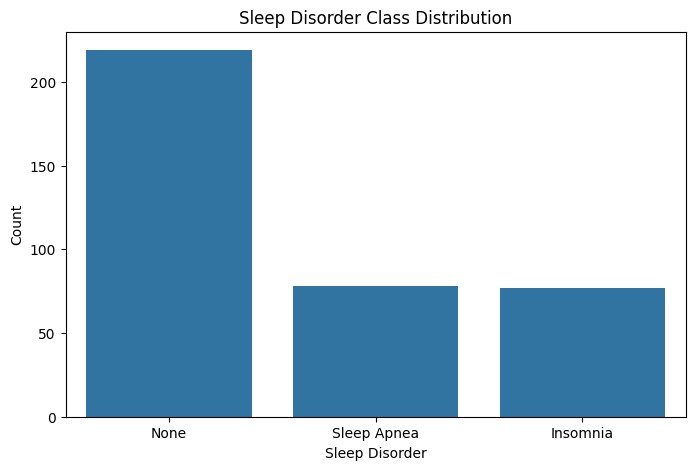

In [139]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x=y,
    order=y.value_counts().index
)

plt.title('Sleep Disorder Class Distribution')
plt.xlabel('Sleep Disorder')
plt.ylabel('Count')

plt.show()

In [70]:
###train and test 

In [140]:
from sklearn.model_selection import train_test_split
x_train,x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [141]:
print("Training Features:", x_train.shape)
print("Testing Features:", x_test.shape)

print("\nTraining Target:")
print(y_train.value_counts())

print("\nTesting Target:")
print(y_test.value_counts())

Training Features: (299, 45)
Testing Features: (75, 45)

Training Target:
Sleep Disorder
None           175
Sleep Apnea     62
Insomnia        62
Name: count, dtype: int64

Testing Target:
Sleep Disorder
None           44
Sleep Apnea    16
Insomnia       15
Name: count, dtype: int64


In [73]:
#feature scaling

In [142]:
from sklearn.preprocessing import StandardScaler
numeric_features = [
    'Age',
    'Sleep Duration',
    'Quality of Sleep',
    'Physical Activity Level',
    'Stress Level',
    'Heart Rate',
    'Daily Steps'
]

In [143]:
preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), numeric_features)
    ],
    remainder='passthrough'
)

In [144]:
###Model training and comparison


In [145]:
models = {

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    'SVM': SVC(),

    'KNN': KNeighborsClassifier(),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    )

}

In [146]:
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(x_train, y_train)

    y_pred = pipeline.predict(x_test)

    results.append({
        'Model': name,
        'Balancing': 'Without Balancing',
        'Accuracy': accuracy_score(y_test, y_pred) * 100,
        'Precision': precision_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        ) * 100,
        'Recall': recall_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        ) * 100,
        'F1 Score': f1_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        ) * 100
    })

    trained_models[name] = pipeline

    print(name, "completed!")

Logistic Regression completed!
Decision Tree completed!
Random Forest completed!
SVM completed!
KNN completed!
Gradient Boosting completed!


In [148]:
balanced_models = {}

for name, model in models.items():

    pipeline = ImbPipeline([
        ('preprocessor', preprocessor),
        ('sampler', RandomOverSampler(random_state=42)),
        ('model', model)
    ])

    pipeline.fit(x_train, y_train)

    y_pred = pipeline.predict(x_test)

    results.append({
        'Model': name,
        'Balancing': 'Random Oversampling',
        'Accuracy': accuracy_score(y_test, y_pred) * 100,
        'Precision': precision_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        ) * 100,
        'Recall': recall_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        ) * 100,
        'F1 Score': f1_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        ) * 100
    })

    balanced_models[name] = pipeline

    print(name, "completed with balancing!")

Logistic Regression completed with balancing!
Decision Tree completed with balancing!
Random Forest completed with balancing!
SVM completed with balancing!
KNN completed with balancing!
Gradient Boosting completed with balancing!


In [149]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

results_df.round(2)

,Model,Balancing,Accuracy,Precision,Recall,F1 Score
0,SVM,Without Balancing,97.33,96.30,95.56,95.66
1,Logistic Regression,Without Balancing,94.67,92.06,92.71,92.25
2,Logistic Regression,Random Oversampling,94.67,92.06,92.71,92.25
3,Gradient Boosting,Without Balancing,94.67,91.63,92.71,92.14
4,KNN,Without Balancing,93.33,90.37,92.10,90.95
5,Decision Tree,Without Balancing,93.33,90.00,91.96,90.86
6,SVM,Random Oversampling,93.33,89.58,90.63,90.07
7,Random Forest,Without Balancing,92.00,89.63,88.55,89.06
8,Gradient Boosting,Random Oversampling,89.33,85.42,89.68,87.06
9,Decision Tree,Random Oversampling,85.33,80.21,84.76,81.87


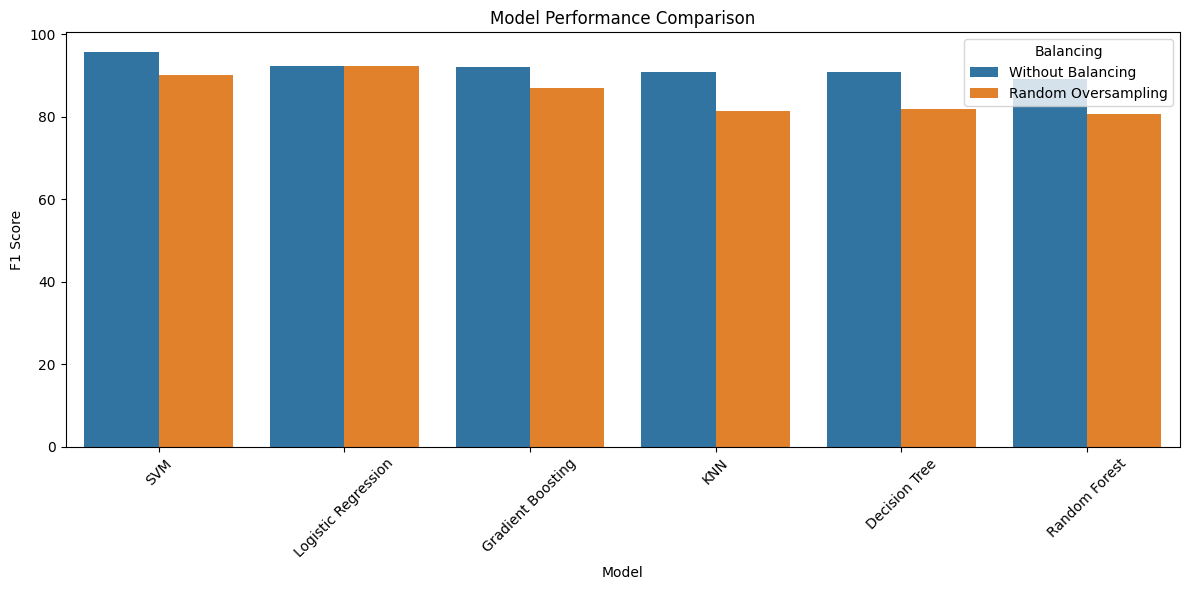

In [150]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='F1 Score',
    hue='Balancing'
)

plt.title('Model Performance Comparison')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
###testing svm

In [151]:
svm_model = Pipeline([
    ('preprocessor', preprocessor),

    ('model', SVC(
        kernel='rbf',
        C=1,
        class_weight='balanced',
        random_state=42
    ))
])

In [152]:
svm_model.fit(x_train, y_train)

y_pred_svm = svm_model.predict(x_test)

In [153]:
print(
    "SVM Accuracy:",
    accuracy_score(y_test, y_pred_svm)
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

SVM Accuracy: 0.96

Classification Report:
              precision    recall  f1-score   support

    Insomnia       0.93      0.87      0.90        15
        None       1.00      0.98      0.99        44
 Sleep Apnea       0.89      1.00      0.94        16

    accuracy                           0.96        75
   macro avg       0.94      0.95      0.94        75
weighted avg       0.96      0.96      0.96        75


Confusion Matrix:
[[13  0  2]
 [ 1 43  0]
 [ 0  0 16]]


In [ ]:
##testing random forest

In [155]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),

    ('model', RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42
    ))
])

In [156]:
rf_model.fit(x_train, y_train)

y_pred_rf = rf_model.predict(x_test)

In [157]:
print(
    "Random Forest Accuracy:",
    accuracy_score(y_test, y_pred_rf)
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

    Insomnia       1.00      0.87      0.93        15
        None       0.96      0.98      0.97        44
 Sleep Apnea       0.82      0.88      0.85        16

    accuracy                           0.93        75
   macro avg       0.93      0.91      0.91        75
weighted avg       0.94      0.93      0.93        75


Confusion Matrix:
[[13  0  2]
 [ 0 43  1]
 [ 0  2 14]]


In [158]:
##cross validation

In [159]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [160]:
cv_scores = cross_val_score(
    svm_model,
    x_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

In [161]:
print("Cross-validation scores:", cv_scores)

print("\nMean CV Accuracy:", cv_scores.mean())

print("Standard Deviation:", cv_scores.std())

Cross-validation scores: [0.88333333 0.91666667 0.9        0.91666667 0.84745763]

Mean CV Accuracy: 0.8928248587570622
Standard Deviation: 0.02583261900023396


In [162]:
###Hyperparameter tuning using GridSearchCV

In [163]:
param_grid = {

    'model__C': [0.1, 1, 10, 100],

    'model__kernel': ['rbf', 'linear'],

    'model__gamma': ['scale', 'auto'],

    'model__class_weight': ['balanced']

}

In [164]:
grid_search = GridSearchCV(
    estimator=svm_model,
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

In [165]:
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__C': [0.1, 1, ...], 'model__class_weight': ['balanced'], 'model__gamma': ['scale', 'auto'], 'model__kernel': ['rbf', 'linear']}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('scaler', ...)]"


In [ ]:
###Evaluate tuned SVM

In [166]:
best_svm_model = grid_search.best_estimator_

y_pred_tuned = best_svm_model.predict(x_test)

In [167]:
print(
    "Tuned SVM Accuracy:",
    accuracy_score(y_test, y_pred_tuned)
)

Tuned SVM Accuracy: 0.9466666666666667


In [168]:
print(
    classification_report(
        y_test,
        y_pred_tuned
    )
)

              precision    recall  f1-score   support

    Insomnia       0.87      0.87      0.87        15
        None       1.00      0.98      0.99        44
 Sleep Apnea       0.88      0.94      0.91        16

    accuracy                           0.95        75
   macro avg       0.92      0.93      0.92        75
weighted avg       0.95      0.95      0.95        75



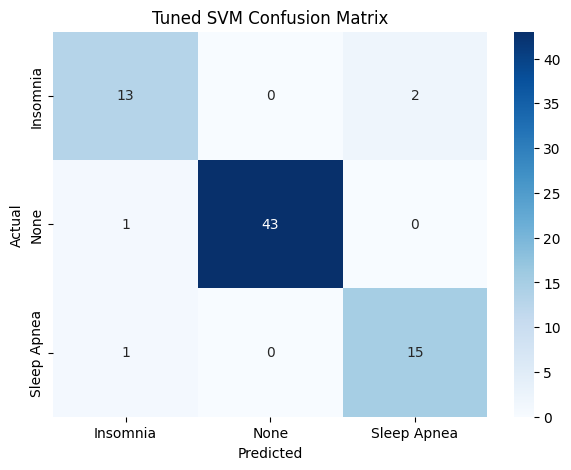

In [169]:
cm = confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=best_svm_model.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_svm_model.classes_,
    yticklabels=best_svm_model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned SVM Confusion Matrix")

plt.show()

In [ ]:
#####Check overfitting and underfitting

In [170]:
y_train_pred = best_svm_model.predict(x_train)

train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

test_accuracy = accuracy_score(
    y_test,
    y_pred_tuned
)

train_f1 = f1_score(
    y_train,
    y_train_pred,
    average='macro'
)

test_f1 = f1_score(
    y_test,
    y_pred_tuned,
    average='macro'
)

print("Training Accuracy:", train_accuracy * 100)

print("Testing Accuracy:", test_accuracy * 100)

print("\nTraining F1 Score:", train_f1 * 100)

print("Testing F1 Score:", test_f1 * 100)

Training Accuracy: 91.9732441471572
Testing Accuracy: 94.66666666666667

Training F1 Score: 90.66882532476464
Testing F1 Score: 92.14211076280043


In [171]:
####Select the final model

In [172]:
final_model = best_svm_model

print("Final Model Selected: Tuned SVM")

Final Model Selected: Tuned SVM


In [173]:
final_predictions = final_model.predict(x_test)

final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

print("Final Model Accuracy:", final_accuracy * 100)

Final Model Accuracy: 94.66666666666667


In [174]:
print(
    classification_report(
        y_test,
        final_predictions
    )
)

              precision    recall  f1-score   support

    Insomnia       0.87      0.87      0.87        15
        None       1.00      0.98      0.99        44
 Sleep Apnea       0.88      0.94      0.91        16

    accuracy                           0.95        75
   macro avg       0.92      0.93      0.92        75
weighted avg       0.95      0.95      0.95        75



In [175]:
os.makedirs('../models', exist_ok=True)

In [176]:
joblib.dump(
    final_model,
    '../models/svm_sleep_disorder_model.pkl'
)

print("Final tuned SVM model saved successfully!")

Final tuned SVM model saved successfully!


In [177]:
test_predictions = loaded_model.predict(x_test)

print(
    "Loaded Model Accuracy:",
    accuracy_score(y_test, test_predictions) * 100
)

Loaded Model Accuracy: 96.0
